# 12. Observability and model comparison

## Problem

A readiness answer is slow or wrong. Determine whether the failure came from retrieval, context selection, generation, orchestration or authorization without exporting private policy text.

## Learning objectives

Create actual Langfuse spans; inspect trace parentage and timings; verify privacy defaults; compare controlled trials; distinguish measured usage from estimates and missing data.

Run top to bottom in a fresh kernel. The lab uses actual model calls, tools and temporary local storage. Configure the services before execution. Every plotted value declares its measurement kind.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
os.chdir(ROOT)
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings( deep_lab_mode="live", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "live" and not settings.langfuse_enabled

## Concept explanation

## Trace structure

A trace represents one logical request or unit of work.

Spans or observations describe its internal operations.

The trace should make it possible to answer:

- Which model configuration was used?
- Which tools were called, with what validated arguments?
- Which evidence IDs were retrieved?
- Which source revisions were considered?
- Where did latency accumulate?
- Was an action approved, edited, rejected, or stale?
- Which saved artifact resulted from the run?

These are observable facts. Debugging should not depend on exposing hidden model reasoning.

## Langfuse instrumentation

Your repository already provides optional Langfuse tracing and privacy controls.

The notebook records actual provider/retrieval timings and reported usage. Enable RUN_LANGFUSE_EXPORT=1 with configured credentials to exercise external export. Verification disables export. Automated unit tests check SDK parentage and exporter isolation.

The same instrumentation can be expressed with decorators or manual observations.

The important design is the trace hierarchy, not the specific syntax.

Langfuse's SDKs use OpenTelemetry concepts and support nested observations and evaluation workflows. The repository's declared `langfuse>=5,<6` contract aligns with the Python v5 major.

## Privacy-aware tracing

Avoid storing raw prompts and responses by default when they may contain confidential information.

An informative trace can often use evidence IDs, query hashes, model identifiers, result counts, timings, and error classifications.

```
{
  "run_id": "run-123",
  "thread_id": "thread-456",
  "operation": "hybrid_retrieval",
  "keyword_results": 10,
  "vector_results": 10,
  "final_results": 4,
  "duration_ms": 125,
  "status": "success"
}
```

These values are illustrative.

Also remember that metadata itself can contain sensitive data. Hashing a short or predictable secret is not necessarily sufficient anonymization.

The safest approach depends on organizational data classification, retention, and threat model.

## Diagnosing failure types

A useful diagnostic method follows the execution sequence.

| Symptom                               | Most useful first inspection                 |
| ------------------------------------- | -------------------------------------------- |
| Correct document absent               | Retrieval candidates, index, source revision |
| Correct passage retrieved but omitted | Context selection and truncation             |
| Evidence present but answer false     | Claim generation and support check           |
| Wrong tool chosen                     | Tool schema and model trajectory             |
| Repeated tool calls                   | Agent policy and loop limits                 |
| Save occurred unexpectedly            | Authorization and approval logs              |
| Duplicate brief                       | Idempotency records and write timeline       |
| Slow request                          | Span durations and model/tool resource usage |

This separation prevents you from changing prompts when the problem is actually in the search index.

## Bounded repair loops

A model may produce an answer without citations even though the retrieval result contains good evidence.

Your repository already implements a limited citation-repair mechanism for live mode.

That is a useful pattern if it is bounded and observable.

A general repair policy might be:

```
Generate answer
    â†“
Validate required structure
    â†“
If invalid and repair budget remains:
    provide targeted feedback
    â†“
Regenerate once
    â†“
Validate again
    â†“
Accept or fail safely
```

Avoid unbounded self-criticism loops.

The validator should provide concrete feedback, such as "claim C2 cites an unknown evidence ID," rather than a vague instruction to make the answer better.

## Model selection

Different models can vary in tool-calling reliability, structured output quality, instruction following, latency, context capacity, and resource requirements.

Northstar should evaluate models on its own task distribution.

Do not assume that a model with a larger parameter count is automatically better for every Northstar task.

### **Controlled comparison**

Use the same dataset and, as far as possible, the same retrieval settings, prompts, tool contracts, inference parameters, and hardware conditions.

Record:

| Dimension              | Why it matters                     |
| ---------------------- | ---------------------------------- |
| Task success           | Core usefulness                    |
| Claim support          | Factual reliability                |
| Tool-call correctness  | Agent reliability                  |
| Appropriate abstention | Avoiding unsupported answers       |
| Latency                | User experience                    |
| Context requirements   | Capacity planning                  |
| Peak memory/VRAM       | Local feasibility                  |
| Tokens per second      | Local inference throughput         |
| Hosted API cost        | Operating expense where applicable |

### **Local inference versus hosted pricing**

A hosted API often charges according to input tokens, output tokens, and provider-specific pricing.

Local Ollama inference has different economics.

You may not pay a per-token provider bill, but you still consume CPU/GPU resources, memory, power, and engineering time.

Approximate local operating cost can be modeled as:

$$ C_{\text{local}} = C_{\text{electricity}} + C_{\text{hardware amortization}} + C_{\text{operations}} $$

This is not directly comparable to hosted token prices without accounting for workload, utilization, capacity, and service-level requirements.

No model benchmark or cost claim in this course should be considered measured until an experiment actually produces the corresponding data.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

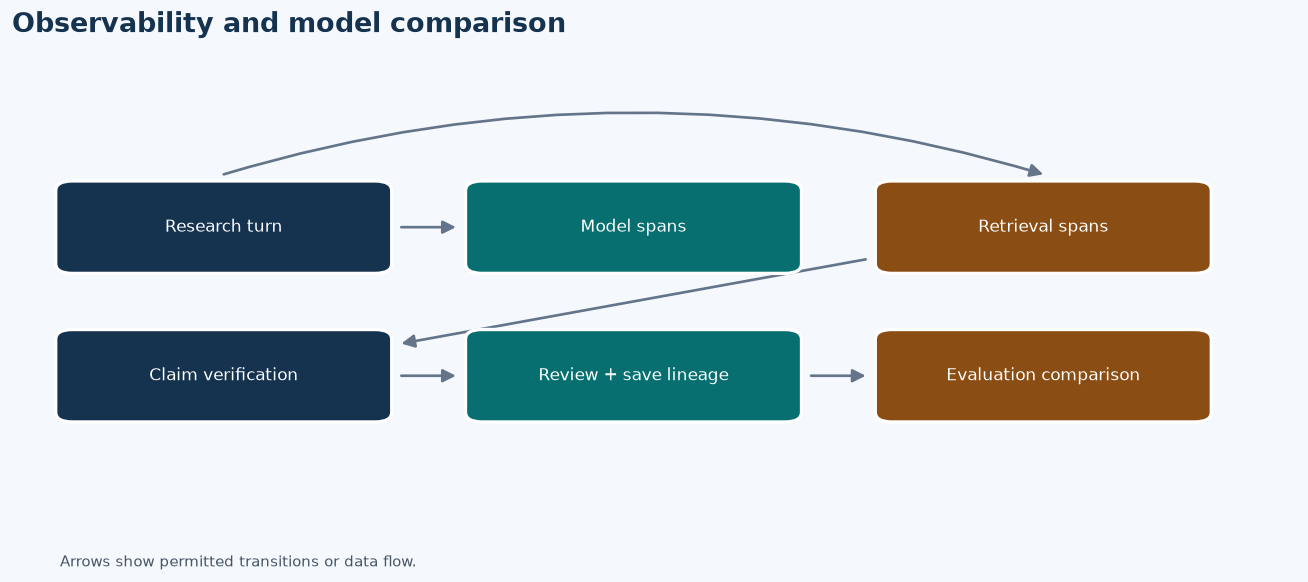

In [2]:
display(diagram('Observability and model comparison', ['Research turn', 'Model spans', 'Retrieval spans', 'Claim verification', 'Review + save lineage', 'Evaluation comparison'], [(0, 1), (0, 2), (2, 3), (3, 4), (4, 5)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
from time import perf_counter
from contextlib import contextmanager
from deep_agent_lab.model_lab import course_model,invoke_record
from langchain.messages import HumanMessage
events = []
@contextmanager
def timed(name):
    start = perf_counter()
    try:
        yield
    finally:
        events.append({"name":name,"start":start,"end":perf_counter()})
with timed("provider inference"):
    measured = invoke_record(course_model(),[HumanMessage("Explain why citations need provenance.")])
print(measured)


{'measurement_kind': 'live measurement', 'latency_ms': 24562.965000004624, 'messages': [{'content': 'Explain why citations need provenance.', 'additional_kwargs': {}, 'response_metadata': {}, 'type': 'human', 'name': None, 'id': None}], 'text': 'Citations require **provenance**—the record of a source\'s origin, history, and chain of custody—because they serve as the foundational mechanism for trust, verification, and intellectual integrity in any field that relies on evidence-based reasoning (such as science, law, journalism, and academia).\n\nWithout provenance, a citation is merely a reference to a text without context, rendering it potentially misleading or useless. Here is a detailed breakdown of why provenance is essential:\n\n### 1. Verification and Fact-Checking\nThe primary function of a citation is to allow readers to locate the original source and verify the claim being made. Provenance provides the necessary metadata to do this:\n*   **Authenticity:** It confirms that the do

## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Inspect the actual service configuration and returned observations in each cell.

In [4]:
from deep_agent_lab.tracing import Tracing
from deep_agent_lab.knowledge import search_knowledge
export_settings = Settings(deep_lab_mode="live", langfuse_enabled=os.getenv("RUN_LANGFUSE_EXPORT") == "1")
tracing = Tracing(export_settings)
with timed("retrieval"):
    evidence = search_knowledge(settings,"production restore",top_k=3)
with tracing.span("course.observability",metadata={"evidence_count":len(evidence)}):
    print("Actual tracing configuration:",tracing.status())
print("Actual provider usage:",measured["usage"])


Actual tracing configuration: {'status': 'disabled'}
Actual provider usage: {'input_tokens': 20, 'output_tokens': 719, 'total_tokens': 739}


## Code walkthrough

The experiment records actual model and retrieval operations and prints the production tracing configuration. External export uses RUN_LANGFUSE_EXPORT=1 with configured credentials. The application wrapper suppresses input and output content by default and records sanitized exception types. Metadata still needs a deliberate schema because content suppression cannot sanitize arbitrary values. A trace records what happened, while an evaluation judges whether it was correct. Compare models with the same cases, prompts, tool contracts, retrieval and hardware conditions; retain each trial.

## Interactive experiments

Plot the actual captured span durations. Parent spans contain child time, so summing all spans double-counts work. Use a timeline to understand overlap.

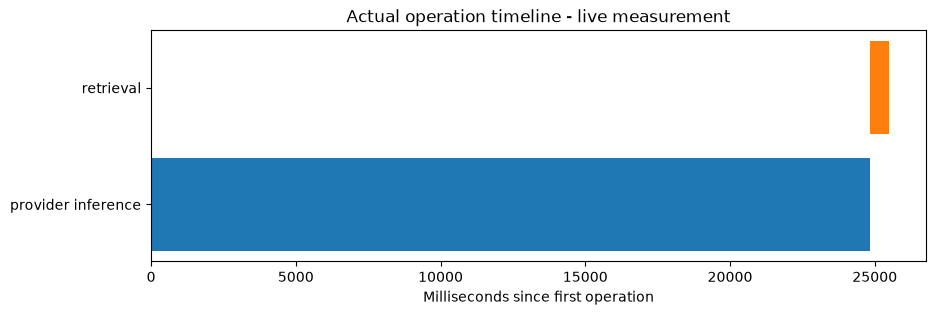

In [5]:
origin = min(event["start"] for event in events)
fig,ax = plt.subplots(figsize=(10,3))
for index,event in enumerate(events):
    ax.barh(index,(event["end"]-event["start"])*1000,left=(event["start"]-origin)*1000)
ax.set_yticks(range(len(events)),[event["name"] for event in events])
ax.set_xlabel("Milliseconds since first operation")
ax.set_title("Actual operation timeline - live measurement")
display(fig)
plt.close("all")


## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
print("Exporter state:",tracing.status())
print("Unavailable usage/cost fields remain null.")
assert measured["measurement_kind"] == "live measurement"


Exporter state: {'status': 'disabled'}
Unavailable usage/cost fields remain null.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert all(event["end"] >= event["start"] for event in events)
assert measured["latency_ms"] > 0
assert settings.langfuse_capture_content is False


## Exercise

Calculate observed search and model time without inventing token counts or prices. Describe which additional measurements are needed for hosted and local cost estimates.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
durations = {event["name"]:(event["end"]-event["start"])*1000 for event in events}
print("Live operation durations",durations,"provider usage",measured["usage"],"cost",None)
tracing.close()


Live operation durations {'provider inference': 24835.796500003198, 'retrieval': 658.3564000029583} provider usage {'input_tokens': 20, 'output_tokens': 719, 'total_tokens': 739} cost None


## Trade-offs and further reading

Capture only telemetry you can use and retain responsibly. The timeline records the actual operations executed in this kernel. Hosted token prices, power, VRAM and hardware amortization require separate measured inputs; a missing value is not zero.

[Primary source 1](https://langfuse.com/docs/observability/sdk/overview) Â· [Primary source 2](https://langfuse.com/docs/observability/data-model)

## Integrated service extension

Configure the actual services described in `docs/operations.md`. This cell executes
real retrieval and model calls. Inspect source revisions, tool results and evidence gaps.
Model output still requires claim support review. External telemetry export is disabled.


In [9]:
RUN_LIVE = True
if RUN_LIVE:
    from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
    live = Settings(_env_file=ROOT / ".env", deep_lab_mode="live", langfuse_enabled=False)
    live.deep_lab_state_dir = Path(scratch.name) / "extension"
    with open_checkpointer(live) as cp:
        service = AgentService(live, cp)
        try:
            result = service.run(RunRequest(
                prompt="Who approves a production restore? Cite the policy."))
            print(result.model_dump_json(indent=2))
            assert result.evidence and not result.unknown_citations
        finally:
            service.close()


{
  "thread_id": "a538652ba3904e9bbcfaf17814c20486",
  "status": "completed",
  "answer": "Based on the policy search results, here is who approves a production restore:\n\n**The database operations lead must approve a production restore.**\n\nThis is stated in the backup-policy document:\n\n> \"To restore accidentally deleted customer records, open a restore request with the database operations team. **The database operations lead must approve a production restore**. Restore into an isolated database first, verify the requested records, and agree on the recovery plan before changing production.\" [[fbac2beaa4c7]]\n\n**Key approval process steps:**\n1. Open a restore request with the database operations team\n2. **Database operations lead approves** the production restore\n3. Restore into an isolated database first\n4. Verify the requested records\n5. Agree on the recovery plan before changing production",
  "evidence": [
    {
      "id": "8689ba038dbf7103d7964482372c286fecd73e9c2441d

In [10]:
plt.close('all')
scratch.cleanup()
print('All executed module assertions passed.')

All executed module assertions passed.
